# Baseline Feature Workflow

이 노트북은 공개 동일 종 음원으로 만든 1차 기준선 파이프라인을 한 번에 점검하기 위한 실험 노트북이다.

흐름:
1. 매니페스트 확인
2. 특성추출 산출물 확인
3. 기준선 리포트 요약
4. confusion matrix 확인
5. 단일 파일 예측 결과 확인

In [1]:
from pathlib import Path
import json
import csv
import numpy as np
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd().resolve().parent.parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
ROOT

WindowsPath('C:/Users/kmnoh/maemi_translater')

In [2]:
manifest_path = ROOT / 'data-workspace' / 'metadata' / 'inat_candidate_manifest.csv'
manifest_df = pd.read_csv(manifest_path)
manifest_df.head()

,species_code,common_name_ko,scientific_name,inat_query_name,region_scope,observation_id,sound_id,quality_grade,license_code,place_guess,observed_on,source_url,file_url,local_raw_path,local_derived_path
0,chammaemi,참매미,Hyalessa maculaticollis,Hyalessa maculaticollis,korea,307907510,1610933,needs_id,cc-by-nc,"Jecheon-si, Chungcheongbuk-do, South Korea",2025-08-21,https://www.inaturalist.org/observations/30790...,https://static.inaturalist.org/sounds/1610933....,data-workspace/raw_audio/inat_candidates/chamm...,data-workspace/derived_audio/inat_candidates/c...
1,chammaemi,참매미,Hyalessa maculaticollis,Hyalessa maculaticollis,korea,306520443,1607180,research,cc-by-nc,"Seonhak-dong, Incheon, Incheon, KR",2025-08-15,https://www.inaturalist.org/observations/30652...,https://static.inaturalist.org/sounds/1607180....,data-workspace/raw_audio/inat_candidates/chamm...,data-workspace/derived_audio/inat_candidates/c...
2,chammaemi,참매미,Hyalessa maculaticollis,Hyalessa maculaticollis,korea,305355623,1600241,research,cc-by,"South Korea, Incheon, Jung-gu, Hwarangmok-ro 1...",2025-08-11,https://www.inaturalist.org/observations/30535...,https://static.inaturalist.org/sounds/1600241....,data-workspace/raw_audio/inat_candidates/chamm...,data-workspace/derived_audio/inat_candidates/c...
3,chammaemi,참매미,Hyalessa maculaticollis,Hyalessa maculaticollis,korea,305132381,1599220,needs_id,cc-by-nc,대한민국 구리시 토평도서관.e편한세상아파트,2025-08-10,https://www.inaturalist.org/observations/30513...,https://static.inaturalist.org/sounds/1599220....,data-workspace/raw_audio/inat_candidates/chamm...,data-workspace/derived_audio/inat_candidates/c...
4,chammaemi,참매미,Hyalessa maculaticollis,Hyalessa maculaticollis,korea,304905703,1599455,research,cc-by-nc,"Songdo-dong, Incheon, Incheon, KR",2025-08-09,https://www.inaturalist.org/observations/30490...,https://static.inaturalist.org/sounds/1599455....,data-workspace/raw_audio/inat_candidates/chamm...,data-workspace/derived_audio/inat_candidates/c...


In [3]:
manifest_df.groupby('species_code').size().sort_index()

species_code
aemaemi          40
chammaemi        35
malmaemi         40
sseureummaemi    34
teolmaemi        20
yujimaemi        26
dtype: int64

In [4]:
features_npz = ROOT / 'ml-workspace' / 'artifacts' / 'features' / 'inat_candidate_features.npz'
features_meta = ROOT / 'ml-workspace' / 'artifacts' / 'features' / 'inat_candidate_features_metadata.csv'
report_path = ROOT / 'ml-workspace' / 'reports' / 'inat_candidate_feature_report.json'
assets_dir = ROOT / 'ml-workspace' / 'reports' / 'assets'

features_blob = np.load(features_npz, allow_pickle=True)
features_blob.files

['X', 'feature_version', 'window_sec', 'hop_sec']

In [5]:
X = features_blob['X']
print('shape:', X.shape)
print('feature_version:', features_blob['feature_version'])
print('window_sec:', features_blob['window_sec'])
print('hop_sec:', features_blob['hop_sec'])

shape: (2017, 52)
feature_version: mfcc20_plus_spectral_stats_v1
window_sec: 3.0
hop_sec: 1.5


In [6]:
feature_meta_df = pd.read_csv(features_meta)
feature_meta_df.head()

,feature_index,window_id,species_code,common_name_ko,scientific_name,observation_id,sound_id,license_code,quality_grade,region_scope,audio_path,start_sec,end_sec,window_sec,hop_sec
0,0,chammaemi_1610933_000,chammaemi,참매미,Hyalessa maculaticollis,307907510,1610933,cc-by-nc,needs_id,korea,data-workspace\derived_audio\inat_candidates\c...,0.0,3.0,3.0,1.5
1,1,chammaemi_1610933_001,chammaemi,참매미,Hyalessa maculaticollis,307907510,1610933,cc-by-nc,needs_id,korea,data-workspace\derived_audio\inat_candidates\c...,1.5,4.5,3.0,1.5
2,2,chammaemi_1610933_002,chammaemi,참매미,Hyalessa maculaticollis,307907510,1610933,cc-by-nc,needs_id,korea,data-workspace\derived_audio\inat_candidates\c...,3.0,6.0,3.0,1.5
3,3,chammaemi_1610933_003,chammaemi,참매미,Hyalessa maculaticollis,307907510,1610933,cc-by-nc,needs_id,korea,data-workspace\derived_audio\inat_candidates\c...,4.5,7.5,3.0,1.5
4,4,chammaemi_1610933_004,chammaemi,참매미,Hyalessa maculaticollis,307907510,1610933,cc-by-nc,needs_id,korea,data-workspace\derived_audio\inat_candidates\c...,6.0,9.0,3.0,1.5


In [7]:
feature_meta_df.groupby('species_code').size().sort_index()

species_code
aemaemi          455
chammaemi        393
malmaemi         350
sseureummaemi    349
teolmaemi        202
yujimaemi        268
dtype: int64

In [8]:
report = json.loads(report_path.read_text(encoding='utf-8'))
summary = {
    'accuracy': report['metrics']['accuracy'],
    'macro_avg': report['metrics']['macro avg'],
    'weighted_avg': report['metrics']['weighted avg'],
}
summary

{'accuracy': 0.7089737233515121,
 'macro_avg': {'precision': 0.7012477956252187,
  'recall': 0.6968668851339608,
  'f1-score': 0.6984748602570825,
  'support': 2017.0},
 'weighted_avg': {'precision': 0.7086420099221475,
  'recall': 0.7089737233515121,
  'f1-score': 0.708307841500039,
  'support': 2017.0}}

In [9]:
per_class = pd.DataFrame({
    label: report['metrics'][label]
    for label in report['dataset_summary']['classes']
}).T[['precision', 'recall', 'f1-score', 'support']]
per_class

,precision,recall,f1-score,support
aemaemi,0.677895,0.707692,0.692473,455.0
chammaemi,0.672330,0.704835,0.688199,393.0
malmaemi,0.756677,0.728571,0.742358,350.0
sseureummaemi,0.797583,0.756447,0.776471,349.0
teolmaemi,0.541436,0.485149,0.511749,202.0
yujimaemi,0.761566,0.798507,0.779599,268.0


In [10]:
pd.DataFrame(report['confusion_matrix']['off_diagonal']).head(10)

,true,pred,count
0,chammaemi,aemaemi,59
1,aemaemi,chammaemi,53
2,teolmaemi,yujimaemi,42
3,malmaemi,aemaemi,35
4,malmaemi,chammaemi,32
5,sseureummaemi,chammaemi,31
6,teolmaemi,aemaemi,30
7,aemaemi,malmaemi,28
8,aemaemi,sseureummaemi,28
9,chammaemi,malmaemi,24


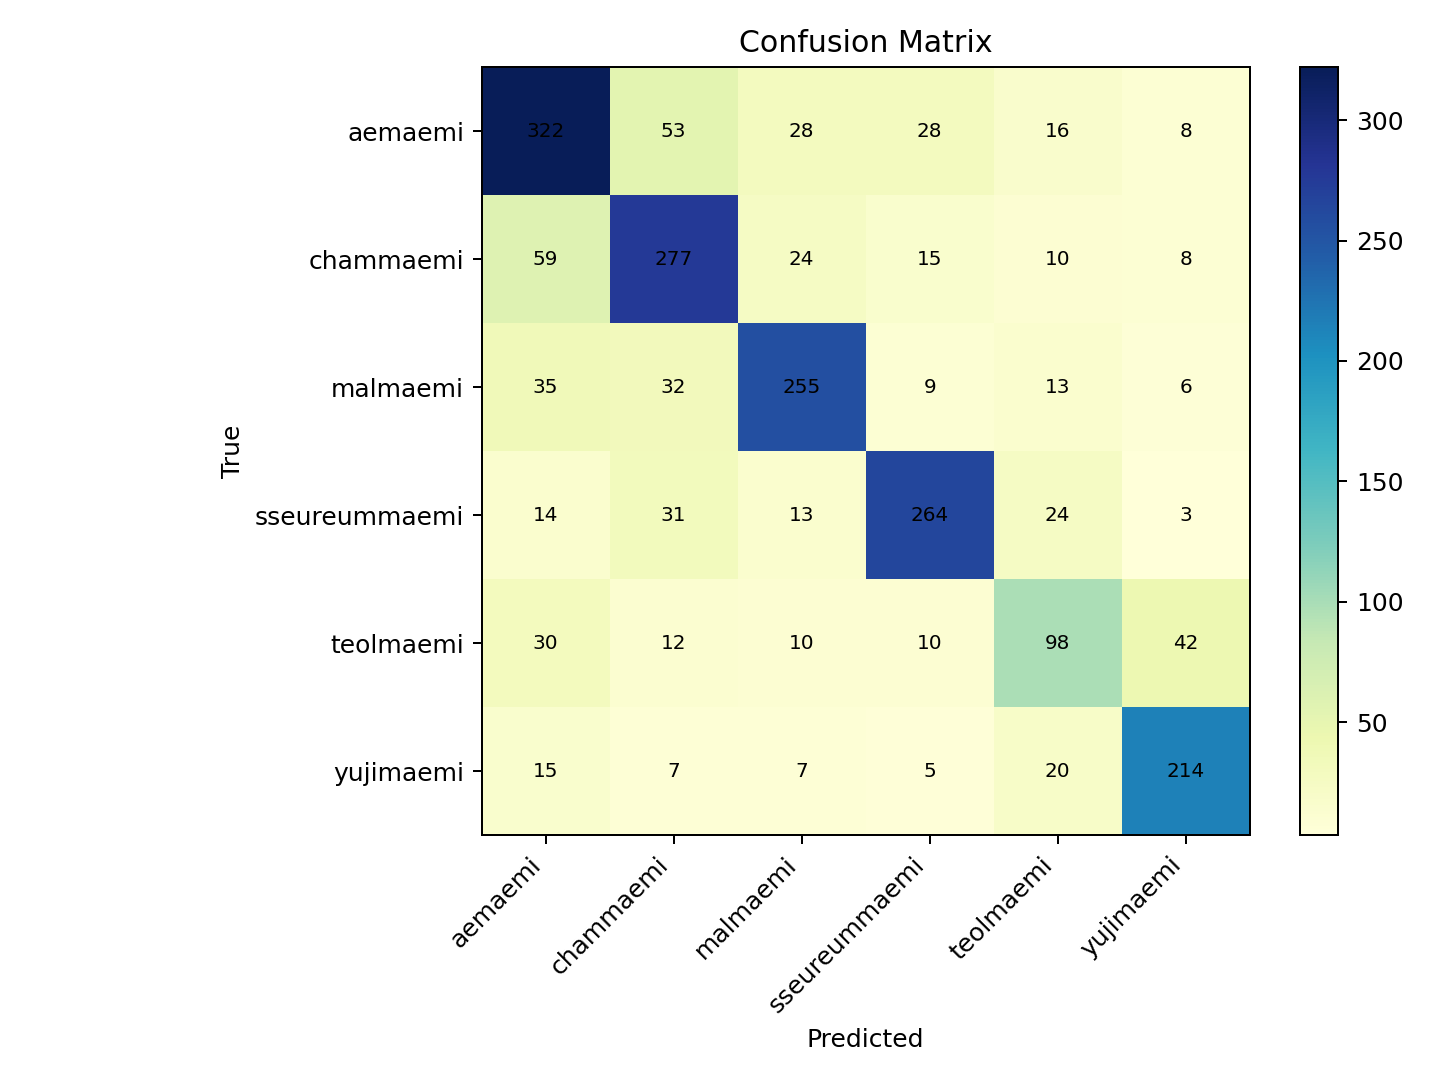

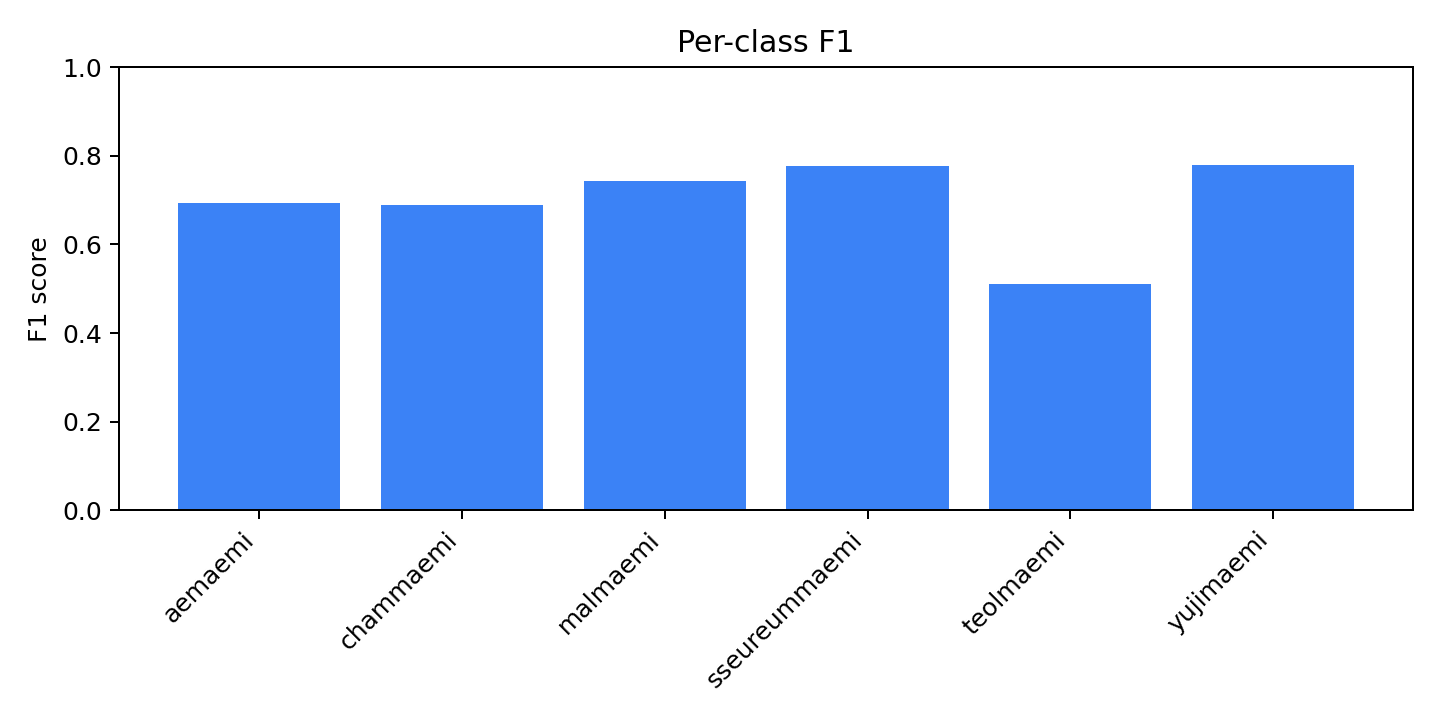

In [11]:
display(Image(filename=str(assets_dir / 'confusion_matrix.png')))
display(Image(filename=str(assets_dir / 'per_class_f1.png')))

In [12]:
sample_prediction_path = ROOT / 'ml-workspace' / 'reports' / 'sample_prediction_chammaemi.json'
sample_prediction = json.loads(sample_prediction_path.read_text(encoding='utf-8'))
pd.DataFrame(sample_prediction['aggregate_ranking']).head(3)

,label,mean_probability,vote_count
0,chammaemi,0.996547,24
1,malmaemi,0.001971,0
2,yujimaemi,0.001348,0


## 재실행 명령

터미널에서 아래 순서로 다시 만들 수 있다.

```powershell
.\.venv\Scripts\python.exe .\scripts\extract_manifest_features.py .\data-workspace\metadata\inat_candidate_manifest.csv --features-out .\ml-workspace\artifacts\features\inat_candidate_features.npz --metadata-out .\ml-workspace\artifacts\features\inat_candidate_features_metadata.csv
.\.venv\Scripts\python.exe .\scripts\train_baseline_from_features.py .\ml-workspace\artifacts\features\inat_candidate_features.npz .\ml-workspace\artifacts\features\inat_candidate_features_metadata.csv --report-out .\ml-workspace\reports\inat_candidate_feature_report.json --model-out .\ml-workspace\artifacts\inat_candidate_feature_model.joblib
.\.venv\Scripts\python.exe .\scripts\render_baseline_report_assets.py .\ml-workspace\reports\inat_candidate_feature_report.json --out-dir .\ml-workspace\reports\assets
```